# Underlying Inflation Dynamics  
### Reproducing and Extending Institutional Macro Analysis with Public Data

## Motivation

Institutional macro teams often focus on underlying inflation pressure rather than 
headline noise, especially when assessing policy implications.

This notebook reproduces a subset of that analysis using public macroeconomic data,
and extends it with simple persistence and short-term momentum indicators.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datetime import datetime

plt.style.use("seaborn-v0_8-whitegrid")


from fredapi import Fred

fred = Fred(api_key="")  #use your API key here!

## Data Sources

- United States: Federal Reserve Economic Data (FRED)
- Euro Area: ECB SDMX API
- Switzerland: Swiss National Bank (SNB)

Public data are used for reproducibility. In a production environment,
the data ingestion layer can be replaced by Bloomberg or internal databases
without changing downstream analysis.

=== RAW PULL (df_raw) ===
shape: (948, 2)
date range: 1947-01-01 → 2025-12-01
missing values:
 cpi_headline      1
cpi_core        121
dtype: int64

head:


,cpi_headline,cpi_core
1947-01-01,21.48,NaN
1947-02-01,21.62,NaN
1947-03-01,22.00,NaN
1947-04-01,22.00,NaN
1947-05-01,21.95,NaN



tail:


,cpi_headline,cpi_core
2025-08-01,323.364,329.793
2025-09-01,324.368,330.542
2025-10-01,NaN,NaN
2025-11-01,325.031,331.068
2025-12-01,326.030,331.860



=== MONTHLY GRID (df) ===
shape: (948, 2)
inferred freq: MS
missing values:
 cpi_headline      1
cpi_core        121
dtype: int64
missing dates (if any): [Timestamp('1947-01-01 00:00:00'), Timestamp('1947-02-01 00:00:00'), Timestamp('1947-03-01 00:00:00'), Timestamp('1947-04-01 00:00:00'), Timestamp('1947-05-01 00:00:00'), Timestamp('1947-06-01 00:00:00'), Timestamp('1947-07-01 00:00:00'), Timestamp('1947-08-01 00:00:00'), Timestamp('1947-09-01 00:00:00'), Timestamp('1947-10-01 00:00:00')] ...
number of missing dates: 121

=== OVERLAP SAMPLE (df_both) ===
shape: (827, 2)
date range: 1957-01-01 → 2025-12-01
missing values:
 cpi_headline    0
cpi_core        0
dtype: int64

=== OVERLAP SAMPLE ON REGULAR GRID (df_both_grid) ===
shape: (828, 2)
inferred freq: MS
missing values:
 cpi_headline    1
cpi_core        1
dtype: int64
missing dates in df_both_grid: DatetimeIndex(['2025-10-01'], dtype='datetime64[ns]', freq='MS')


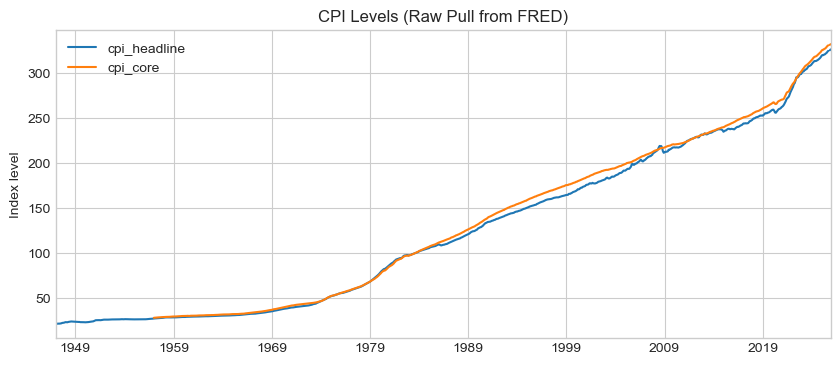

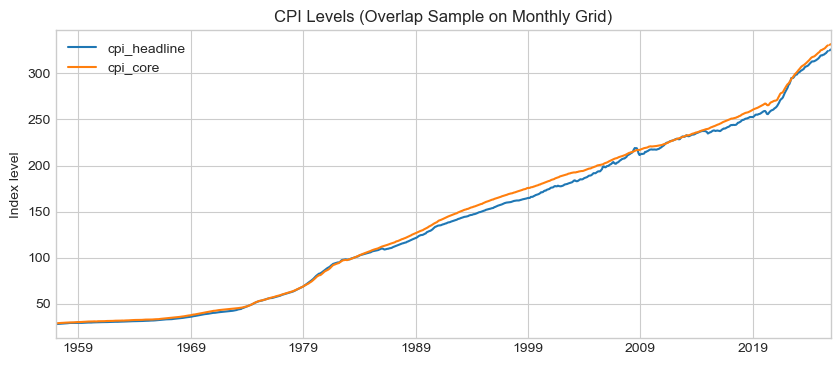

In [2]:

# Data 


#  Define series (levels) 
series = {
    "cpi_headline": "CPIAUCSL",  # CPI All Urban Consumers (headline)
    "cpi_core": "CPILFESL"       # CPI Less Food & Energy (core)
}

# Pull series into a DataFrame
df_raw = pd.DataFrame({name: fred.get_series(code) for name, code in series.items()})
df_raw.index = pd.to_datetime(df_raw.index)
df_raw = df_raw.sort_index()

# Reindex to complete monthly grid (MS = Month Start)
full_months = pd.date_range(df_raw.index.min(), df_raw.index.max(), freq="MS")
df = df_raw.reindex(full_months)

# overlap sample: months where BOTH series exist 
df_both = df.dropna(subset=["cpi_headline", "cpi_core"])

# clean-grid version of overlap sample (keeps a regular MS index) 
full_months_both = pd.date_range(df_both.index.min(), df_both.index.max(), freq="MS")
df_both_grid = df_both.reindex(full_months_both)


# checks / diagnostics


print("=== RAW PULL (df_raw) ===")
print("shape:", df_raw.shape)
print("date range:", df_raw.index.min().date(), "→", df_raw.index.max().date())
print("missing values:\n", df_raw.isna().sum())
print("\nhead:")
display(df_raw.head())
print("\ntail:")
display(df_raw.tail())

print("\n=== MONTHLY GRID (df) ===")
print("shape:", df.shape)
print("inferred freq:", pd.infer_freq(df.index))
print("missing values:\n", df.isna().sum())

missing_dates_df = df[df.isna().any(axis=1)].index
print("missing dates (if any):", list(missing_dates_df[:10]), "..." if len(missing_dates_df) > 10 else "")
print("number of missing dates:", len(missing_dates_df))

print("\n=== OVERLAP SAMPLE (df_both) ===")
print("shape:", df_both.shape)
print("date range:", df_both.index.min().date(), "→", df_both.index.max().date())
print("missing values:\n", df_both.isna().sum())

print("\n=== OVERLAP SAMPLE ON REGULAR GRID (df_both_grid) ===")
print("shape:", df_both_grid.shape)
print("inferred freq:", pd.infer_freq(df_both_grid.index))
print("missing values:\n", df_both_grid.isna().sum())

missing_dates_both = df_both_grid[df_both_grid.isna().any(axis=1)].index
print("missing dates in df_both_grid:", missing_dates_both)


# plots 


df_raw.plot(figsize=(10, 4), title="CPI Levels (Raw Pull from FRED)")
plt.ylabel("Index level")
plt.show()

df_both_grid.plot(figsize=(10, 4), title="CPI Levels (Overlap Sample on Monthly Grid)")
plt.ylabel("Index level")
plt.show()

In [7]:
#Transformation: 

inflation_yoy = 100 * df_both_grid.pct_change(12, fill_method=None)
inflation_yoy = inflation_yoy.dropna()

inflation_3m = 100 * ((df_both_grid / df_both_grid.shift(3))**4 - 1)
inflation_3m = inflation_3m.dropna()

In [9]:
print("YoY range:", inflation_yoy.index.min().date(), "→", inflation_yoy.index.max().date())
print("3m SAAR range:", inflation_3m.index.min().date(), "→", inflation_3m.index.max().date())

display(inflation_yoy.tail())
display(inflation_3m.tail())

YoY range: 1958-01-01 → 2025-12-01
3m SAAR range: 1957-04-01 → 2025-12-01


,cpi_headline,cpi_core
2025-07-01,2.731801,3.048603
2025-08-01,2.939220,3.112191
2025-09-01,3.022700,3.025543
2025-11-01,2.711969,2.618879
2025-12-01,2.653312,2.648966


,cpi_headline,cpi_core
2025-07-01,2.280732,2.755719
2025-08-01,3.519216,3.645516
2025-09-01,3.616305,3.640865
2025-11-01,2.078073,1.555416
2025-12-01,2.065330,1.604521


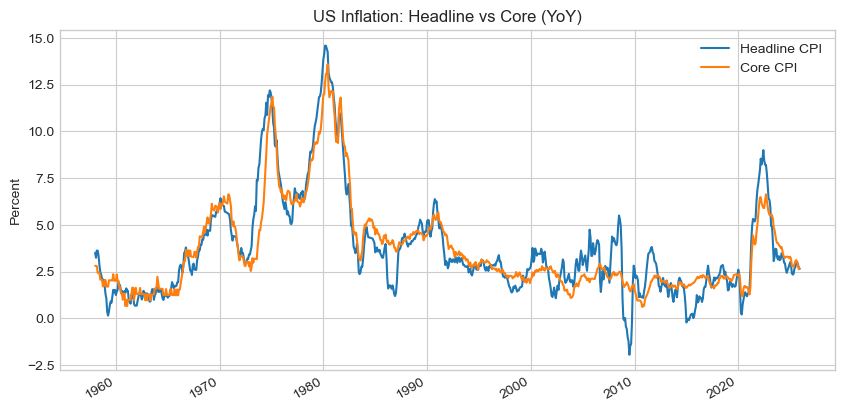

In [11]:
fig, ax = plt.subplots(figsize=(10,5))

inflation_yoy["cpi_headline"].plot(ax=ax, label="Headline CPI")
inflation_yoy["cpi_core"].plot(ax=ax, label="Core CPI")

ax.set_title("US Inflation: Headline vs Core (YoY)")
ax.set_ylabel("Percent")
ax.legend()

plt.show()

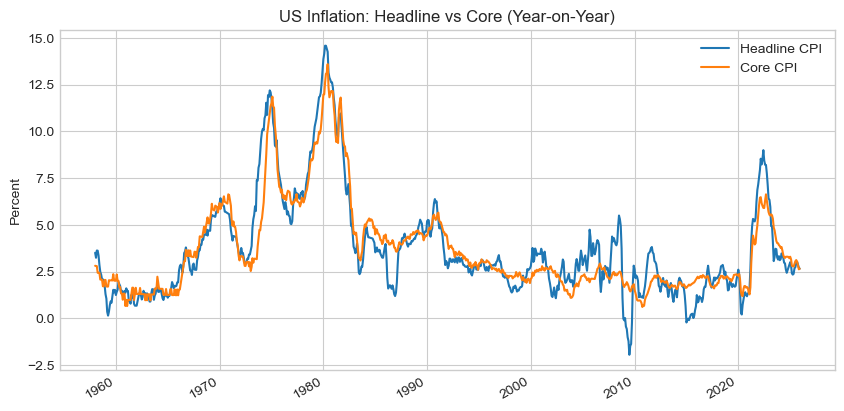

In [13]:
#institutional chart

fig, ax = plt.subplots(figsize=(10,5))

inflation_yoy["cpi_headline"].plot(ax=ax, label="Headline CPI")
inflation_yoy["cpi_core"].plot(ax=ax, label="Core CPI")

ax.set_title("US Inflation: Headline vs Core (Year-on-Year)")
ax.set_ylabel("Percent")
ax.legend()

plt.show()

## Interpretation: Headline vs Core Inflation (YoY)

- Headline inflation is more volatile, reflecting swings in energy and food prices.
- Core inflation is smoother and provides a better signal of underlying inflation pressure.
- Periods where core inflation remains elevated even as headline inflation falls
  tend to coincide with persistent services inflation and tighter labor markets.
- Recent readings show headline and core converging, suggesting reduced energy-driven
  distortions but continued underlying inflation pressure.

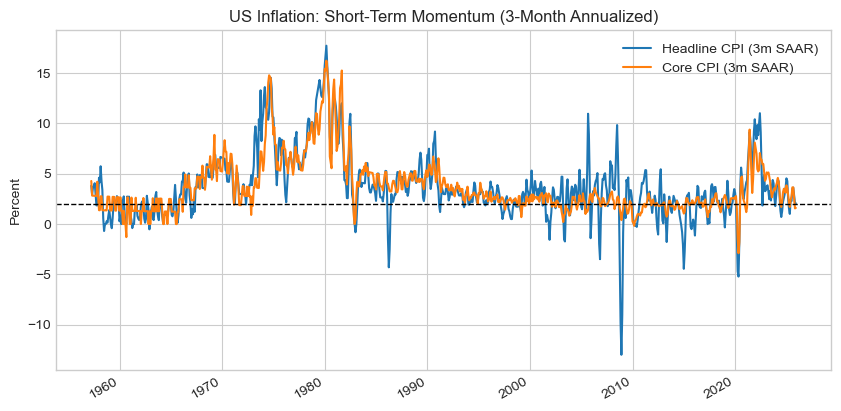

In [16]:
fig, ax = plt.subplots(figsize=(10,5))

inflation_3m["cpi_headline"].plot(ax=ax, label="Headline CPI (3m SAAR)")
inflation_3m["cpi_core"].plot(ax=ax, label="Core CPI (3m SAAR)")

ax.axhline(2, color="black", linestyle="--", linewidth=1)
ax.set_title("US Inflation: Short-Term Momentum (3-Month Annualized)")
ax.set_ylabel("Percent")
ax.legend()

plt.show()

## Interpretation: Short-Term Inflation Momentum

- Short-term annualized measures are more volatile but tend to lead year-on-year inflation.
- Spikes in 3-month momentum often precede sustained moves in headline inflation.
- Recent momentum measures have moderated toward the 2% range, suggesting
  cooling inflation dynamics, though volatility remains elevated.

In [21]:
#Inflation persistence 

window = 12  # 12-month rolling window

core_persistence = inflation_yoy["cpi_core"].rolling(window).apply(
    lambda x: pd.Series(x).autocorr(lag=1),
    raw=False
)

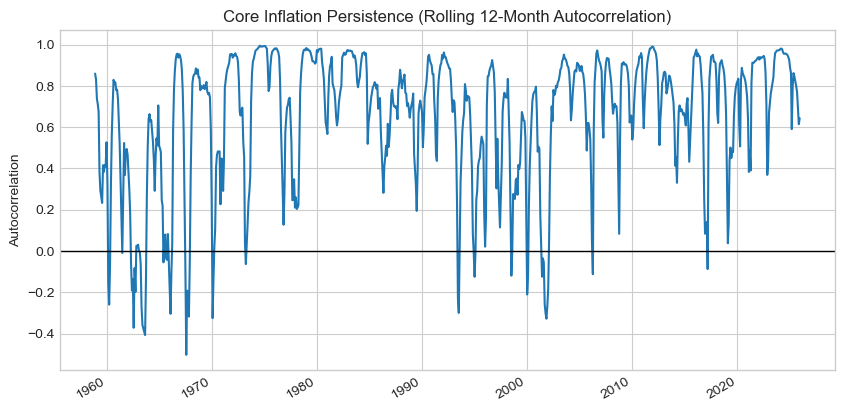

In [23]:
fig, ax = plt.subplots(figsize=(10,5))

core_persistence.plot(ax=ax, color="tab:blue")

ax.axhline(0, color="black", linewidth=1)
ax.set_title("Core Inflation Persistence (Rolling 12-Month Autocorrelation)")
ax.set_ylabel("Autocorrelation")

plt.show()

## Interpretation: Inflation Persistence

- Periods of high persistence indicate that inflation shocks tend to carry forward,
  consistent with entrenched inflation dynamics.
- Low or declining persistence suggests more transitory inflation movements and
  greater effectiveness of disinflationary forces.
- The recent moderation in persistence points to easing inflation pressure,
  though persistence remains elevated relative to pre-pandemic norms.

In [29]:
# Align all needed series on the same date index
tmp = pd.concat(
    {
        "core_yoy": inflation_yoy["cpi_core"],
        "core_3m": inflation_3m["cpi_core"],
        "persistence": core_persistence,
    },
    axis=1
).dropna()

# Rule-based "inflation pressure" regime
pressure_signal = (
    (tmp["core_yoy"] > 2) &
    (tmp["core_3m"] > tmp["core_yoy"]) &
    (tmp["persistence"] > 0.3)
)

latest_date = pressure_signal.index[-1]
print("Date:", latest_date.date())
print("Inflation pressure regime:", "ELEVATED" if pressure_signal.loc[latest_date] else "EASING")

# Optional: show the latest values driving the classification
display(tmp.tail(5))

Date: 2025-12-01
Inflation pressure regime: EASING


,core_yoy,core_3m,persistence
2025-07-01,3.048603,2.755719,0.823234
2025-08-01,3.112191,3.645516,0.799608
2025-09-01,3.025543,3.640865,0.769393
2025-11-01,2.618879,1.555416,0.614610
2025-12-01,2.648966,1.604521,0.643451


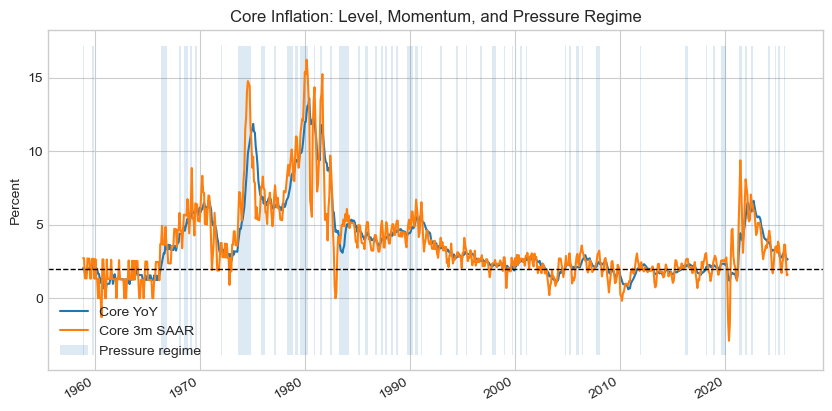

In [31]:
fig, ax = plt.subplots(figsize=(10,5))

tmp["core_yoy"].plot(ax=ax, label="Core YoY")
tmp["core_3m"].plot(ax=ax, label="Core 3m SAAR")

# Shade periods where pressure_signal is True
ax.fill_between(
    pressure_signal.index,
    ax.get_ylim()[0],
    ax.get_ylim()[1],
    where=pressure_signal.values,
    alpha=0.15,
    label="Pressure regime"
)

ax.axhline(2, color="black", linestyle="--", linewidth=1)
ax.set_title("Core Inflation: Level, Momentum, and Pressure Regime")
ax.set_ylabel("Percent")
ax.legend()
plt.show()